In [262]:
import torch
import opt_einsum
import matplotlib.pyplot as plt

from ngo.numericalanalysis.basisfunctions import BSplineBasis, TensorProductBasis
from ngo.numericalanalysis.quadrature import GaussLegendreQuadrature
from ngo.testproblems.steadydiffusion.manufacturedsolutions import *


In [302]:
n_t = 2
n_x = 10
n_y = 10
Q_t = 2
Q_x = 99
Q_y = 99
n_elements_t = 1
n_elements_x = 3
n_elements_y = 3
N = n_t * n_x * n_y

w_q_t = GaussLegendreQuadrature(Q=(Q_t,), n_elements=(n_elements_t,)).w
t_q = GaussLegendreQuadrature(Q=(Q_t,), n_elements=(n_elements_t,)).xi[:,0]
w_q_x = GaussLegendreQuadrature(Q=(Q_x,), n_elements=(n_elements_x,)).w
x_q = GaussLegendreQuadrature(Q=(Q_x,), n_elements=(n_elements_x,)).xi[:,0]
w_q_y = GaussLegendreQuadrature(Q=(Q_y,), n_elements=(n_elements_y,)).w
y_q = GaussLegendreQuadrature(Q=(Q_y,), n_elements=(n_elements_y,)).xi[:,0]
w_q_t = torch.tensor(w_q_t, dtype=torch.float64, device="cuda")
t_q = torch.tensor(t_q, dtype=torch.float64, device="cuda")
w_q_x = torch.tensor(w_q_x, dtype=torch.float64, device="cuda")
x_q = torch.tensor(x_q, dtype=torch.float64, device="cuda")
w_q_y = torch.tensor(w_q_y, dtype=torch.float64, device="cuda")
y_q = torch.tensor(y_q, dtype=torch.float64, device="cuda")

W_q = w_q_t, w_q_x, w_q_y
X_q = t_q, x_q, y_q

In [303]:
basis_t = BSplineBasis(N=n_t, p=1, C=0, dtype=torch.float64, device="cuda")
basis_x = BSplineBasis(N=n_x, p=3, C=2, dtype=torch.float64, device="cuda")
basis_y = BSplineBasis(N=n_y, p=3, C=2, dtype=torch.float64, device="cuda")

phi = TensorProductBasis(bases=(basis_t, basis_x, basis_y))
psi = TensorProductBasis(bases=(basis_t, basis_x, basis_y))
theta = TensorProductBasis(bases=(basis_t, basis_x, basis_y))

In [304]:
def assemble_B(psi, phi, W_q, X_q, derivative_orders=((0,0,0),(0,0,0))):
    """
    Assemble the Kronecker factors of the bilinear form
    B(u,v) = \int \psi(x) \phi(x) dx
    or its derivatives.
    
    Args:
        psi: TensorProductBasis
        phi: TensorProductBasis
        W_q: d tuple of quadrature weights for each dimension, each of shape (Q_i,)
        X_q: d tuple of quadrature points for each dimension of shape (Q_i,)
        derivative_orders: tuple of two tuples, each containing the derivative orders for psi and phi in each dimension.
                           For example, ((0,1,0),(1,0,0)) means no derivative for psi in dim 0, first derivative in dim 1, no derivative in dim 2,
                           and first derivative for phi in dim 0, no derivative in dim 1, no derivative in dim 2.
    Returns:
        F: d tuple of Kronecker factors, each of shape (B,n_i,m_i)
    """
    F = ()
    for i in range(len(X_q)):
        # psi
        # Set operation for psi
        operation = derivative_orders[0][i]
        if operation == 0:
            Psi_i = psi.bases[i].forward(X_q[i]) #shape (B,n,q)
        elif operation == 1:
            Psi_i = psi.bases[i].grad(X_q[i]) #shape (B,n,q)
        # phi
        # Set operation for phi
        operation = derivative_orders[1][i]
        if operation == 0:
            Phi_i = phi.bases[i].forward(X_q[i]) #shape (B,n,q)
        elif operation == 1:
            Phi_i = phi.bases[i].grad(X_q[i]) #shape (B,n,q)
        # F_i = opt_einsum.contract('q,Bmq->Bmq', W_q[i], Psi_i) #shape (B,n,Q)
        # F_i = opt_einsum.contract('Bmq,Bnq->Bmn', F_i, Phi_i) #shape (B,n,m)
        # Assemble in one step
        F_i = opt_einsum.contract('q,Bmq,Bnq->Bmn', W_q[i], Psi_i, Phi_i) #shape (B,n,m)
        F += (F_i,)
    return F

In [305]:
def assemble_T(theta, psi, phi, W_q, X_q, derivative_orders=((0,0,0),(0,0,0),(0,0,0))):
    """
    Assemble the Kronecker factors of the trilinear form
    T(u,v,w) = \int \theta(x) \psi(x) \phi(x) dx
    or its derivatives.

    Args:
        theta: TensorProductBasis
        psi: TensorProductBasis
        phi: TensorProductBasis
        W_q: d tuple of quadrature weights for each dimension, each of shape (Q_i,)
        X_q: d tuple of quadrature points for each dimension of shape (Q_i,)
        derivative_orders: tuple of three tuples, each containing the derivative orders for theta, psi and phi in each dimension.
                           For example, ((0,1,0),(1,0,0),(0,0,1)) means no derivative for theta in dim 0, first derivative in dim 1, no derivative in dim 2,
                           first derivative for psi in dim 0, no derivative in dim 1, no derivative in dim 2,
                           and no derivative for phi in dim 0, no derivative in dim 1, first derivative in dim 2.
    Returns:
        F: d tuple of Kronecker factors, each of shape (B,l_i,m_i,n_i)
    """
    F = ()
    for i in range(len(X_q)):
        # theta
        # Set operation for theta
        operation = derivative_orders[0][i]
        if operation == 0:
            Theta_i = theta.bases[i].forward(X_q[i]) #shape (B,n,q)
        elif operation == 1:
            Theta_i = theta.bases[i].grad(X_q[i]) #shape (B,n,q)
        # psi
        # Set operation for psi
        operation = derivative_orders[1][i]
        if operation == 0:
            Psi_i = psi.bases[i].forward(X_q[i]) #shape (B,n,q)
        elif operation == 1:
            Psi_i = psi.bases[i].grad(X_q[i]) #shape (B,n,q)
        # phi
        # Set operation for phi
        operation = derivative_orders[2][i]
        if operation == 0:
            Phi_i = phi.bases[i].forward(X_q[i]) #shape (B,n,q)
        elif operation == 1:
            Phi_i = phi.bases[i].grad(X_q[i]) #shape (B,n,q)
        # F_i = opt_einsum.contract('q,Blq->Blq', W_q[i], Theta_i) #shape (B,n,Q)
        # F_i = opt_einsum.contract('Blq,Bmq->Blmq', F_i, Psi_i) #shape (B,n,m)
        # F_i = opt_einsum.contract('Blmq,Bnq->Blmn', F_i, Phi_i) #shape (B,n,m)
        # Assemble in one step
        F_i = opt_einsum.contract('q,Blq,Bmq,Bnq->Blmn', W_q[i], Theta_i, Psi_i, Phi_i) #shape (B,n,m)
        F += (F_i,)
    return F

In [306]:
%%timeit
F = assemble_T(theta, psi, phi, W_q=W_q, X_q=X_q, derivative_orders=((0,0,0),(0,0,0),(0,0,0)))

7.7 ms ± 464 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [307]:
F[2].shape

torch.Size([1, 10, 10, 10])

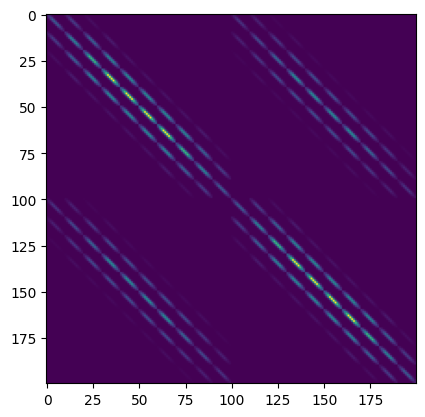

In [308]:
plt.imshow(F_full[0].cpu())

In [310]:
N_samples = 100
lambda_min = torch.tensor([0.1,0.1,0.1], device='cuda', dtype=torch.float64)
lambda_max = torch.tensor([0.1,0.1,0.1], device='cuda', dtype=torch.float64)
d = len(lambda_min)
b_min_u = -1 #torch.tensor([1], device='cuda', dtype=torch.float64)
b_max_u = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_min_u = 0 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_max_u  = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
device = 'cuda'
dtype = torch.float64
n = (3,3)

In [311]:
u = ManufacturedSolution(N_samples, d, lambda_min, lambda_max, b_min_u, b_max_u, c_min_u, c_max_u, device, dtype, n)

/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, dtype=self.dtype, device=self.device)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, dtype=self.dtype, device=self.device)


In [312]:
b_min_theta = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
b_max_theta = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_min_theta = 0 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_max_theta  = 0.2 #torch.tensor([1], device='cuda', dtype=torch.float64)

In [313]:
theta = ManufacturedSolution(N_samples, d, lambda_min, lambda_max, b_min_theta, b_max_theta, c_min_theta, c_max_theta, device, dtype, n)

In [314]:
torch.cuda.empty_cache()
u.forward(X_q).shape

torch.Size([1, 2, 99, 99])

In [315]:
f = Forcing(theta, u)

In [316]:
f.forward(X_q).shape

torch.Size([100, 2, 99, 99])

In [ ]:
def assemble_L(psi, f, W_q, X_q, derivative_orders):
    """
    Assemble the Kronecker factors of the linear form
    L(v) = \int f(x) \psi(x) dx
    or its derivatives.
    
    Args:
        psi: TensorProductBasis
        f: ManufacturedSolution
        W_q: d tuple of quadrature weights for each dimension, each of shape (Q_i,)
        X_q: d tuple of quadrature points for each dimension of shape (Q_i,)
        derivative_orders: tuple containing the derivative orders for psi in each dimension.
                           For example, (0,1,0) means no derivative for psi in dim 0, first derivative in dim 1, no derivative in dim 2.
    Returns:
        L: Tensor of shape (B,n_1,n_2,...,n_d)  
    """
    f_q = f.forward(X_q) 
    L = f_q
    for i in range(len(X_q)):
        # psi
        # Set derivative order for psi
        operation = derivative_orders[i]
        if operation == 0:
            Psi_i = psi.bases[i].forward(X_q[i]) 
        elif operation == 1:
            Psi_i = psi.bases[i].grad(X_q[i])
        # Contract over dimension i
        L = opt_einsum.contract('q,Bnq,Bq...->Bn...', W_q[i], Psi_i, L)
        # Move contracted index to the end
        L = L.moveaxis(1,-1)
    return L

In [324]:
L = assemble_L(psi, f, W_q, X_q, derivative_orders=(0,0,0))

In [325]:
L.shape

torch.Size([100, 2, 10, 10])

In [320]:
%%timeit
L = assemble_L(psi, f, W_q, X_q, derivative_orders=(0,0,0))

736 ms ± 45.5 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
